# Artificial Intelligence in Health Care - Exercise 2
## Convolutional Neural Networks for Image Classification

Mitglieder: Elbischger Selina, Krauss Marco
Jahrgang: EHT25

Das Ziel der Übung ist es ein CNN (Convolusional neural Network) zu trainieren um damit verschiedene histologische Bilder von Darmgewebe der passenden Kategorie (Darmschleimhaut, Tumorgewebe, Muskel, etc. ) zuordnen zu können.

In [42]:
#Imports and Configs
import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

#Datensatzimporte
#%pip install medmnist  #install package medmnist
from medmnist import INFO

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
#print("keras", keras.__version__, "| backend", keras.backend.backend())

### 1 Data Pre-Processing and Partitioning [2P]
Der Datensatz ist bereits in Trainings- Validierungs- und Testsets aufgeteilt. Die Bilder und Labels werden geladen. Im ersten Schritt verschaffen wir uns einen Überblick über den Datensatz. Hierfür wird für jede der 9 Klassen ein Bild mit dem passenden Label angezeigt. Weiters wird:  
* One-Hot-Encoding der Klassenlabels
* Pixelwerte von 0-255 auf 0-1
* Klassenverteilung ermitteln

Für die Zuordnung der nummerischen Label 0-8 zu den Klassen recherchierten wir die Datensatzbeschreibung und fanden diese in folgendem Repo: https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py .  

<center>

| Label | Klasse |
| :---: | :--- |
| 0 | Fettgewebe |
| 1 | Hintergrund |
| 2 | Debris |
| 3 | Lymphozyten |
| 4 | Schleim |
| 5 | Glatte Muskulatur |
| 6 | normale Darmschleimhaut |
| 7 | Tumorassoziiertes Stroma |
| 8 | Kolorektales Adenokarzinom-Epithel |

</center>

Keys =  ['x_train', 'x_val', 'x_test', 'y_train', 'y_val', 'y_test']
Label 0: adipose
Label 1: background
Label 2: debris
Label 3: lymphocytes
Label 4: mucus
Label 5: smooth muscle
Label 6: normal colon mucosa
Label 7: cancer-associated stroma
Label 8: colorectal adenocarcinoma epithelium


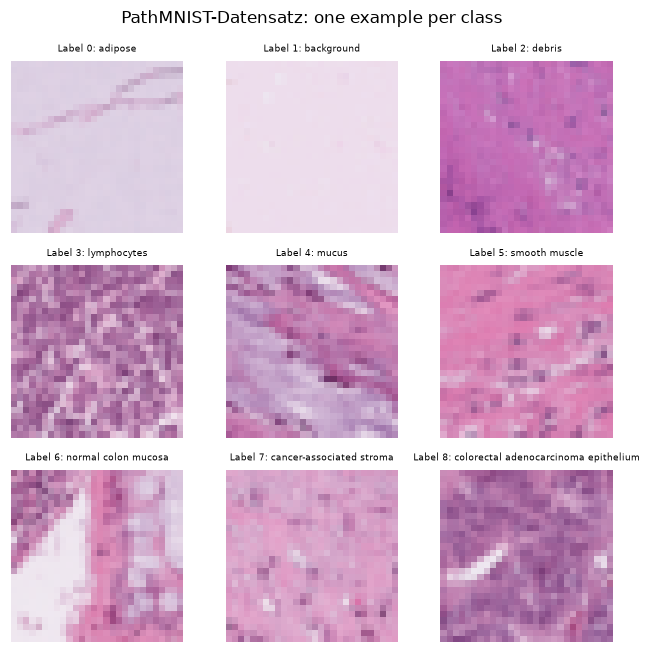

In [43]:
#Datensatz laden und Ausgabe der Keys
path = np.load('C:\\Users\\selin\\Documents\\GitLab\\KIGW\\data\\path_train.npz')
print("Keys = ", list(path.keys()))

#Aufteilen in Trainings-, Validierungs- und Testdaten
x_train, y_train = path['x_train'], path['y_train']
x_val, y_val = path['x_val'], path['y_val']
x_test, y_test = path['x_test'], path['y_test']

# Zuordnung der Labels zu den Klassen
class_labels = INFO['pathmnist']['label']
#display(len(class_labels))  # Anzahl der Klassen

for label, class_name in class_labels.items():
    print(f"Label {label}: {class_name}")

#Darstellung eines Bildes pro Klasse
labels = y_train.ravel()        # Eindimensionales Array
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for i, ax in enumerate(axes.ravel()):       #axes.ravel() gibt ein eindimensionales Array der Achsen zurück -> weil die sind derzeit 3x3 angeordnet
    image_index = np.where(labels == i)[0][0]  # Index des ersten Bildes der Klasse i
    ax.imshow(x_train[image_index], cmap='gray')    # Darstellung des Bildes
    ax.set_title(f"Label {i}: {class_labels[str(i)]}", fontsize=6)  # Titel mit Label und Klassenname   #str(1) weil die keys in class_labels strings sind
    ax.axis('off')    # Achsen ausblenden
fig.suptitle("PathMNIST-Datensatz: one example per class", fontsize=11)
plt.tight_layout()
plt.show()

    




In [44]:
#One-hot-Encoding der Labels
y_train_oh = keras.utils.to_categorical(y_train, num_classes=len(class_labels))
y_val_oh = keras.utils.to_categorical(y_val, num_classes=len(class_labels))
y_test_oh = keras.utils.to_categorical(y_test, num_classes=len(class_labels))

#Skalierung der Bilder auf den Wertebereich [0, 1] -> wichtig für NN zum lernen ; Bildinformation bleibt erhalen weil 128 ist dann irgendein Kommawert 0,5xy
x_train = x_train.astype('float32') / 255.0
x_val = x_val.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

#Klassenverteilung des Trainingsdatensatzes
classes, counts = np.unique(y_train.ravel(), return_counts=True)  #eindeutigen Klassen und Anzahl der Bilder pro Klasse

#Übersicht in Dataframe
class_distribution = pd.DataFrame({'Klasse/Label': classes, 
                                   'Anzahl Bilder': counts,
                                   'prozentueller Anteil': (counts / len(y_train) * 100).round(2)})
display(class_distribution)

,Klasse/Label,Anzahl Bilder,prozentueller Anteil
0,0,9366,10.41
1,1,9509,10.57
2,2,10360,11.51
3,3,10401,11.56
4,4,8006,8.90
5,5,12182,13.54
6,6,7886,8.76
7,7,9401,10.45
8,8,12885,14.32


### 2 Fully-Connected Neural Network [3P]
Als Basline zum vergleichen wird ein Fully connected neural Network mit folgender Netzwerkarchitektur gebaut:  
- 3 hidden layers (1024, 512 and 128)
- RELU Funktion
- 1 outputlayer mit softmax-Aktivierungsfunktion

Training mit categorical-cross entropy, early stopping und adam optimizer mit α = 0.001; eventuell Dropout.

In [41]:

#Fuktion zum Kompilieren, Trainieren und Evaluieren des Modells inkl. Ausgabe
def train_model(model, epochs=25, tag=""):
    model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=[keras.metrics.CategoricalAccuracy(name="acc")])

    #Early Stopping -> verhinder Overfitting -> validierunsfehler überwachen ; wenn nach 5 Epochen keine Verbesserung -> abbruch & besten Gewichte
    early_stop = keras.callbacks.EarlyStopping(monitor="val_acc", 
                                               mode="max",
                                               patience=5, 
                                               restore_best_weights=True)

    #Model trainieren
    h = model.fit(x_train, y_train_oh,                      #Trainingsdaten und korrekte Labels
                  validation_data=(x_val, y_val_oh),        #Validierungsdaten und korrekte Labels
                  epochs=epochs,
                  batch_size=128,         #Anzahl der Bilder für Berechnung des Gradienten/Gewicht pro Schritt
                  verbose=0, 
                  callbacks=[early_stop])
    
    
    prob = model.predict(x_test, batch_size=128) # Wahrscheinlichkeiten für jede Klasse für jedes Testbild
    pred = prob.argmax(axis=1)     # Index der Klasse mit der höchsten Wahrscheinlichkeit für jedes Testbild -> liefert eindimensionales Array
    
    test_label = y_test.ravel()  # Eindimensionales Array der Testlabels
    acc = accuracy_score(test_label, pred)      #korrekt vorhergesagte Labels
    auc = roc_auc_score(test_label, prob, multi_class="ovr", average="macro") #ovr=one-vs-rest, average=macro -> Mittelwert über alle Klassen

    n_par = model.count_params()        #Anzahl der trainierbaren Parameter im Modell -> Anzahl der Gewichte und Biases in allen Schichten
    print(f"{tag:<22} test accuracy {acc:.4f}   macro AUROC {auc:.4f}   "
          f"parameters {n_par:,}   epochs {len(h.history['loss'])}")
    return dict(tag=tag, model=model, hist=h, acc=acc, auc=auc, params=n_par,
                prob=prob, pred=pred)


#Netzwerkarchitektur definieren
keras.utils.set_random_seed(SEED)   
dense = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),
    layers.Flatten(),                      # 28*28 Pixel *3Farben(RGB) bei farbbilder -> nach flatten 2352 Werte hintereinander
    layers.Dense(1024, activation="relu"),
    #layers.Dropout(0.3),
    layers.Dense(512, activation="relu"),
    #layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(class_labels), activation="softmax"),            # softmax = Wahrscheinlichkeitsverteilung über mehrere klassen (Gesamt=1)
], name="dense")

res_dense = train_model(dense, tag="dense network")

KeyboardInterrupt: 

was macht --> from_logits=True
was sind trainierbare parameter? Gewichte und die Bias-Werte.